# 03 · Model 1 — Bayesian logistic regression

    p(flies | x) = sigmoid(a + x . b)

Fitted by `scripts/fit_model1.py`; this notebook only reads the saved posteriors.
Rerun the fits with:

    python scripts/fit_model1.py            # Laplace + MCMC, ~25 min
    python scripts/fit_model1.py --no-mcmc  # Laplace only, 4 s

Four questions, in order:

1. Does the Laplace approximation match MCMC? (If not, nothing below can be trusted.)
2. Which chemistry makes a molecule fly, and how sure are we?
3. Are the probabilities honest — better than the random forest's?
4. Does ARD do anything on 50 hand-picked features?

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from scipy import special
from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

TAG = "chem"          # feature block the fits used
ADDITIVE = "formate"
meta = json.loads((PROC / "model1_meta.json").read_text())
meta

{'features': ['chem'],
 'additive': 'formate',
 'n_features': 50,
 'gaussian_scale': 2.5,
 'draws': 1000,
 'tune': 1000,
 'chains': 4,
 'target_accept': 0.95,
 'seed': 20261124}

In [2]:
cur = pd.read_csv(PROC / "wif_curated.csv")
y = cur[f"flies_{ADDITIVE}"].to_numpy()

def laplace(split, prior):
    z = np.load(PROC / f"model1_{TAG}_{ADDITIVE}_{split}_{prior}_laplace.npz", allow_pickle=True)
    return {k: z[k] for k in z.files}

def mcmc(split, prior):
    return az.from_netcdf(PROC / f"model1_{TAG}_{ADDITIVE}_{split}_{prior}_mcmc.nc")

names = list(laplace("random", "ard")["feature_names"])
summary = pd.read_csv(PROC / "model1_summary.csv")
print(f"{len(names)} features")
summary.round(3)

50 features


,prior,posterior,split,features,seconds,AUC,log loss,Brier,divergences
0,gaussian,laplace,random,chem,0.261,0.868,0.456,0.148,NaN
1,gaussian,mcmc,random,chem,316.262,0.868,0.455,0.148,0.0
2,ard,laplace,random,chem,1.334,0.868,0.455,0.148,NaN
3,ard,mcmc,random,chem,343.104,0.869,0.454,0.148,0.0
4,gaussian,laplace,cluster,chem,0.188,0.846,0.484,0.160,NaN
5,gaussian,mcmc,cluster,chem,325.742,0.847,0.484,0.160,0.0
6,ard,laplace,cluster,chem,1.122,0.846,0.485,0.160,NaN
7,ard,mcmc,cluster,chem,342.038,0.846,0.484,0.160,0.0


## 1. Does Laplace match MCMC?

The predictions already agreed to 0.001 AUC. That is a weak test: two very different posteriors
can still predict alike. The real test is per-coefficient — same centre, same width?

Laplace assumes the posterior is a symmetric bell around the mode. MCMC assumes nothing. If the
two line up on the diagonal, the cheap approximation is telling the truth, and every later model
can use it instead of waiting five minutes.

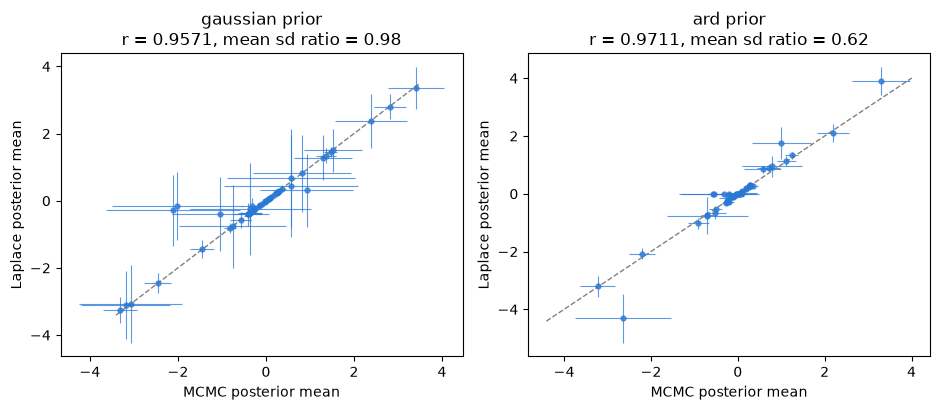

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, prior in zip(axes, ["gaussian", "ard"]):
    lap, mc = laplace("random", prior), mcmc("random", prior)
    b_mc = mc.posterior["b"].to_numpy().reshape(-1, len(names))
    lap_mean, lap_sd = lap["mean"][1:], np.sqrt(np.diag(lap["cov"])[1:])

    ax.errorbar(b_mc.mean(0), lap_mean, xerr=b_mc.std(0), yerr=lap_sd,
                fmt="o", ms=3.5, lw=0.8, alpha=0.75, color="#2a78d6")
    lim = np.array([min(lap_mean.min(), b_mc.mean(0).min()) - 0.1,
                    max(lap_mean.max(), b_mc.mean(0).max()) + 0.1])
    ax.plot(lim, lim, "--", color="0.5", lw=1)
    r = np.corrcoef(b_mc.mean(0), lap_mean)[0, 1]
    sd_ratio = (lap_sd / b_mc.std(0)).mean()
    ax.set_title(f"{prior} prior\nr = {r:.4f}, mean sd ratio = {sd_ratio:.2f}")
    ax.set_xlabel("MCMC posterior mean"); ax.set_ylabel("Laplace posterior mean")
plt.tight_layout(); plt.show()

A `sd ratio` near 1 means Laplace gets the *uncertainty* right too, not just the centre — the part
an approximation usually gets wrong, and the part this whole project depends on.

Watch the ARD panel: the centres track well but the ratio sits near 0.6, so Laplace reports
coefficient intervals about a third too narrow. ARD's posterior has a funnel shape that no
Gaussian can match, and the mode is in its neck. Predictions are unaffected — they average over
the coefficients, and that averaging is dominated by the centre — which is why the AUCs agreed
to 0.001 while the widths do not. So: Laplace is fine for predicting, and for ARD its error bars
on individual coefficients should be read as a lower bound.

## 2. The coefficients of the full model are not interpretable

Read naively, the fit says molecular weight makes a molecule 25× *less* likely to fly while
Chi0v — another measure of molecular size — makes it 29× *more* likely. Both cannot be true.
They are the same quantity pulling in opposite directions.

In [4]:
lap = laplace("random", "ard")
mean, sd = lap["mean"][1:], np.sqrt(np.diag(lap["cov"])[1:])
coef = (pd.DataFrame({"feature": names, "mean": mean, "sd": sd})
          .assign(odds_ratio=lambda d: np.exp(d["mean"]))
          .sort_values("mean"))
pd.concat([coef.head(5), coef.tail(5)]).round(3)

,feature,mean,sd,odds_ratio
33,LabuteASA,-4.307,0.847,0.013
19,MolWt,-3.202,0.360,0.041
22,TPSA,-2.071,0.195,0.126
42,HallKierAlpha,-1.025,0.191,0.359
30,HeavyAtomCount,-0.752,0.634,0.472
31,NHOHCount,1.121,0.175,3.069
24,NumHAcceptors,1.331,0.122,3.785
21,MolMR,1.761,0.547,5.816
37,Chi1v,2.104,0.298,8.196
36,Chi0v,3.905,0.479,49.653


### Why: the size descriptors are the same feature wearing different hats

`RingCount` is *exactly* `NumAromaticRings + NumAliphaticRings`, so the design matrix is
singular and those three coefficients can be shifted arbitrarily without changing a single
prediction. Eight more descriptors all measure molecular size and correlate above 0.9.

This does not hurt prediction — the prior keeps the fit stable, which is why AUC is fine. It
destroys *interpretation*, because the data cannot say how a shared effect should be divided
among features that move together. ARD does not rescue this: it shrinks features that are
useless, not features that are redundant with each other.

In [5]:
from numpy.linalg import inv, svd

tr_mask = cur["split_random"].to_numpy() == "train"
Xdf = pd.read_csv(PROC / "features_chem.csv").drop(columns=["compound_id"])
Xdf = Xdf[names]
Z = (Xdf - Xdf[tr_mask].mean()) / Xdf[tr_mask].std()

size = ["LabuteASA", "MolWt", "Chi0v", "Chi1v", "MolMR", "HeavyAtomCount", "Kappa1"]
print("correlation among the size descriptors:")
print(Z[size].corr().round(2).to_string())

s = svd(Z[tr_mask].to_numpy(), compute_uv=False)
print(f"\ncondition number: {s[0] / s[-1]:.1e}   (above ~1e3 means the fit is ill-posed)")
print("RingCount - (aromatic + aliphatic) max error:",
      float((Xdf["RingCount"] - Xdf["NumAromaticRings"] - Xdf["NumAliphaticRings"]).abs().max()))

correlation among the size descriptors:
                LabuteASA  MolWt  Chi0v  Chi1v  MolMR  HeavyAtomCount  Kappa1
LabuteASA            1.00   0.97   0.98   0.92   0.98            0.99    0.93
MolWt                0.97   1.00   0.95   0.91   0.92            0.95    0.93
Chi0v                0.98   0.95   1.00   0.95   0.97            0.95    0.94
Chi1v                0.92   0.91   0.95   1.00   0.92            0.89    0.87
MolMR                0.98   0.92   0.97   0.92   1.00            0.96    0.89
HeavyAtomCount       0.99   0.95   0.95   0.89   0.96            1.00    0.92
Kappa1               0.93   0.93   0.94   0.87   0.89            0.92    1.00

condition number: 3.5e+15   (above ~1e3 means the fit is ill-posed)
RingCount - (aromatic + aliphatic) max error: 0.0


### Fix: prune to a set the data can actually separate

Drop the worst-inflated feature, recompute, repeat, until every variance inflation factor is
under 10. This keeps one representative of each correlated family and lets its coefficient mean
something. Prediction is not the goal here, so paying a little AUC for an honest answer is the
right trade.

In [6]:
def prune_by_vif(Z: pd.DataFrame, threshold: float = 10.0) -> list[str]:
    """Greedily drop the most collinear feature until every VIF is below the threshold."""
    cols = list(Z.columns)
    while len(cols) > 2:
        C = np.corrcoef(Z[cols].to_numpy().T)
        try:
            vif = np.diag(inv(C))
        except np.linalg.LinAlgError:
            vif = np.diag(np.linalg.pinv(C))
        worst = int(np.argmax(vif))
        if vif[worst] <= threshold:
            break
        cols.pop(worst)
    return cols

keep = prune_by_vif(Z[tr_mask])
print(f"kept {len(keep)} of {len(names)}")
print("dropped:", ", ".join(sorted(set(names) - set(keep))))

kept 34 of 50
dropped: BertzCT, Chi0v, Chi1v, HeavyAtomCount, Kappa1, Kappa2, LabuteASA, MolMR, MolWt, NHOHCount, NOCount, NumAromaticRings, NumHeteroatoms, RingCount, TPSA, has_acid


In [7]:
def fit_laplace_ridge(Zm, y, tr, prior_sd=2.5):
    """Same Laplace fit as the script, with the fixed Gaussian prior, inlined so the
    notebook can refit the pruned feature set in a second."""
    A = np.hstack([np.ones((len(Zm), 1)), Zm])
    prec = np.full(Zm.shape[1], 1 / prior_sd ** 2)
    f = lambda w: np.sum(np.logaddexp(0, A[tr] @ w) - y[tr] * (A[tr] @ w)) + 0.5 * np.sum(prec * w[1:] ** 2)
    g = lambda w: A[tr].T @ (special.expit(A[tr] @ w) - y[tr]) + np.r_[0, prec * w[1:]]
    from scipy import optimize
    w = optimize.minimize(f, np.zeros(A.shape[1]), jac=g, method="L-BFGS-B").x
    p = special.expit(A[tr] @ w)
    H = (A[tr] * (p * (1 - p))[:, None]).T @ A[tr]
    H[1:, 1:] += np.diag(prec)
    H[0, 0] += 0.01
    cov = inv(H)
    return w, np.sqrt(np.diag(cov)), A

w, w_sd, A = fit_laplace_ridge(Z[keep].to_numpy(), y, tr_mask)
te_mask = ~tr_mask
p_pruned = special.expit(A[te_mask] @ w)
print(f"pruned model: AUC {roc_auc_score(y[te_mask], p_pruned):.3f}  "
      f"log loss {log_loss(y[te_mask], p_pruned):.3f}   "
      f"(full model: AUC {summary.query('prior==\"ard\" and posterior==\"laplace\" and split==\"random\"')['AUC'].iloc[0]:.3f})")

interp = (pd.DataFrame({"feature": keep, "mean": w[1:], "sd": w_sd[1:]})
            .assign(odds_ratio=lambda d: np.exp(d["mean"]),
                    OR_lo=lambda d: np.exp(d["mean"] - 1.96 * d["sd"]),
                    OR_hi=lambda d: np.exp(d["mean"] + 1.96 * d["sd"]),
                    clear=lambda d: (d["OR_lo"] - 1) * (d["OR_hi"] - 1) > 0)
            .sort_values("mean"))

pruned model: AUC 0.853  log loss 0.474   (full model: AUC 0.868)


### Which chemistry makes a molecule fly

Coefficients are on standardised features: one standard deviation more of this feature multiplies
the odds of flying by `exp(b)`. A bar whose interval clears 1 is a real effect; one straddling it
is a feature the data cannot speak to.

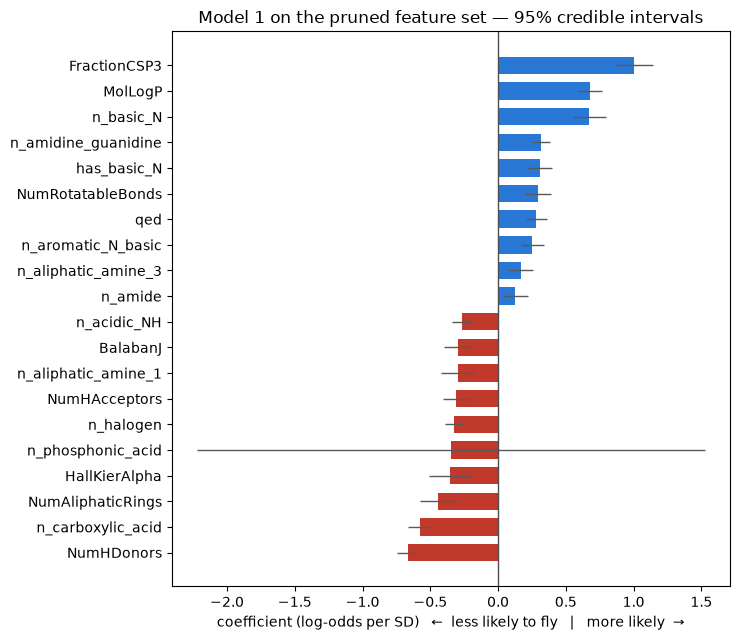

26 of 34 intervals exclude 1


In [8]:
top = pd.concat([interp.head(10), interp.tail(10)])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
colors = ["#c0392b" if m < 0 else "#2a78d6" for m in top["mean"]]
ax.barh(top["feature"], top["mean"], xerr=1.96 * top["sd"],
        color=colors, height=0.68, error_kw=dict(lw=1, ecolor="0.35"))
ax.axvline(0, color="0.3", lw=1)
ax.set_xlabel("coefficient (log-odds per SD)   ←  less likely to fly   |   more likely  →")
ax.set_title("Model 1 on the pruned feature set — 95% credible intervals")
plt.tight_layout(); plt.show()

print(f"{int(interp['clear'].sum())} of {len(interp)} intervals exclude 1")

In [9]:
# the chemistry the proposal predicts: basic nitrogen helps, acids hurt
show = ["has_basic_N", "n_basic_N", "n_aromatic_N_basic", "n_aliphatic_amine_2",
        "n_carboxylic_acid", "n_phenol", "NumHDonors", "MolLogP", "FractionCSP3"]
interp[interp["feature"].isin(show)].set_index("feature").reindex(
    [s for s in show if s in set(interp["feature"])])[
    ["mean", "sd", "odds_ratio", "OR_lo", "OR_hi", "clear"]].round(3)

,mean,sd,odds_ratio,OR_lo,OR_hi,clear
feature,,,,,,
has_basic_N,0.312,0.045,1.366,1.250,1.492,True
n_basic_N,0.674,0.063,1.963,1.735,2.221,True
n_aromatic_N_basic,0.253,0.042,1.288,1.186,1.398,True
n_aliphatic_amine_2,-0.092,0.032,0.912,0.856,0.972,True
n_carboxylic_acid,-0.574,0.045,0.563,0.515,0.615,True
n_phenol,-0.115,0.035,0.891,0.833,0.954,True
NumHDonors,-0.665,0.040,0.514,0.476,0.556,True
MolLogP,0.681,0.045,1.975,1.807,2.159,True
FractionCSP3,1.000,0.072,2.719,2.361,3.132,True


## 3. Are the probabilities honest?

This is the claim the project rests on: not "does it rank molecules correctly" (AUC) but
"when it says 70%, does 70% of that group actually fly". The dashed diagonal is perfect honesty.

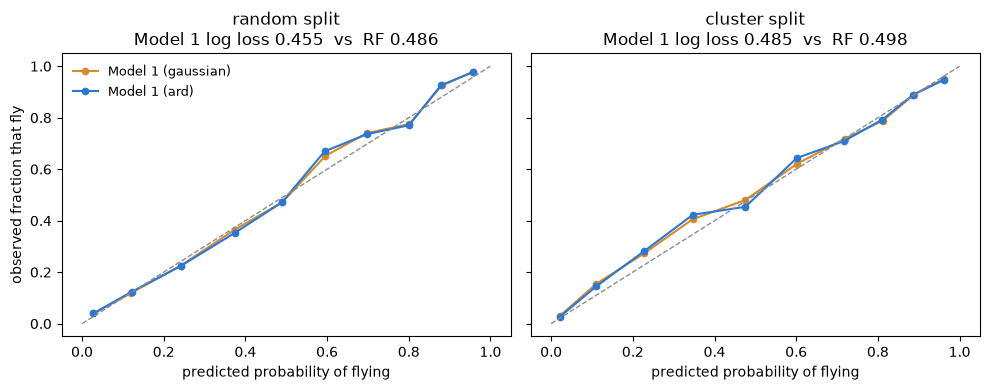

In [10]:
rf_base = pd.read_csv(PROC / "baseline_rf.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, split in zip(axes, ["random", "cluster"]):
    te = np.where(cur[f"split_{split}"].to_numpy() == "test")[0]
    for prior, c in [("gaussian", "#d68a2a"), ("ard", "#2a78d6")]:
        p = laplace(split, prior)["test_pred"]
        frac, pred = calibration_curve(y[te], p, n_bins=10, strategy="quantile")
        ax.plot(pred, frac, "o-", ms=4.5, lw=1.5, color=c, label=f"Model 1 ({prior})")
    ax.plot([0, 1], [0, 1], "--", color="0.55", lw=1)
    rf_row = rf_base[(rf_base["split"] == split) & (rf_base["features"] == "chem")]
    ax.set_title(f"{split} split\nModel 1 log loss "
                 f"{log_loss(y[te], laplace(split, 'ard')['test_pred']):.3f}"
                 f"  vs  RF {rf_row['log loss'].iloc[0]:.3f}")
    ax.set_xlabel("predicted probability of flying")
axes[0].set_ylabel("observed fraction that fly"); axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 4. Did ARD do anything?

ARD learns one prior width per feature, so useless features get squeezed towards zero without
anyone choosing them by hand. `prec` is the learnt precision — large precision means a feature
was shrunk hard.

With 50 hand-picked chemistry features there is little junk to remove, so ARD and the fixed
Gaussian prior should land in nearly the same place. The test that matters is what happens with
2048 Morgan bits, most of which are noise.

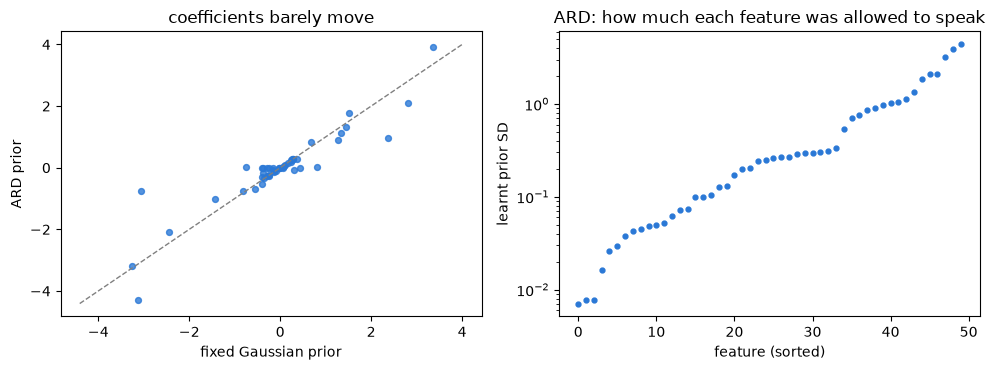

17 features shrunk by more than half under ARD

most suppressed: MinPartialCharge, n_quaternary_N, MaxPartialCharge, NumSaturatedRings, n_sulfonic_acid, n_carboxylic_acid
least suppressed: MolMR, TPSA, Chi1v, MolWt, Chi0v, LabuteASA


In [11]:
g, a = laplace("random", "gaussian"), laplace("random", "ard")
cmp = pd.DataFrame({
    "feature": names,
    "gaussian": g["mean"][1:],
    "ard": a["mean"][1:],
    "ard_prior_sd": 1 / np.sqrt(a["prec"]),
}).assign(shrunk=lambda d: np.abs(d["ard"]) < 0.5 * np.abs(d["gaussian"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(cmp["gaussian"], cmp["ard"], s=18, color="#2a78d6", alpha=0.8)
lim = [cmp[["gaussian", "ard"]].to_numpy().min() - 0.1, cmp[["gaussian", "ard"]].to_numpy().max() + 0.1]
axes[0].plot(lim, lim, "--", color="0.5", lw=1)
axes[0].set_xlabel("fixed Gaussian prior"); axes[0].set_ylabel("ARD prior")
axes[0].set_title("coefficients barely move")

order = cmp.sort_values("ard_prior_sd")
axes[1].semilogy(range(len(order)), order["ard_prior_sd"], "o", ms=3.5, color="#2a78d6")
axes[1].set_xlabel("feature (sorted)"); axes[1].set_ylabel("learnt prior SD")
axes[1].set_title("ARD: how much each feature was allowed to speak")
plt.tight_layout(); plt.show()

print(f"{int(cmp['shrunk'].sum())} features shrunk by more than half under ARD")
print("\nmost suppressed:", ", ".join(order["feature"].head(6)))
print("least suppressed:", ", ".join(order["feature"].tail(6)))

## 5. Where Model 1 stands

Against the random forest on the same 50 features. Model 1 wins on both, and by more on log loss
than on AUC — which is the point: the Bayesian model is not a much better *ranker*, it is a much
better *estimator of its own confidence*.

In [12]:
rows = []
for split in ["random", "cluster"]:
    te = np.where(cur[f"split_{split}"].to_numpy() == "test")[0]
    p = laplace(split, "ard")["test_pred"]
    rf = rf_base[(rf_base["split"] == split) & (rf_base["features"] == "chem")].iloc[0]
    rows += [
        {"split": split, "model": "random forest", "AUC": rf["AUC"],
         "log loss": rf["log loss"], "Brier": rf["Brier"]},
        {"split": split, "model": "Model 1 (ARD)", "AUC": roc_auc_score(y[te], p),
         "log loss": log_loss(y[te], p), "Brier": brier_score_loss(y[te], p)},
    ]
pd.DataFrame(rows).set_index(["split", "model"]).round(3)

AUC  log loss  Brier
split   model                                
random  random forest  0.846     0.486  0.161
        Model 1 (ARD)  0.868     0.455  0.148
cluster random forest  0.838     0.498  0.165
        Model 1 (ARD)  0.846     0.485  0.160

### Next

- feed the 2048 Morgan bits to Model 1 and see whether ARD earns its keep:
  `python scripts/fit_model1.py --features chem morgan --no-mcmc`
- Model 2: censored regression on log peak area, so the 362 zeros stop being thrown away